# Machine Learning Basics: Classification and Regression

**Topics:** exploratory data analysis (EDA), classification, regression

Author: Shirel Azeroual

### Assignment Objectives:
1. Perform Basic Exploratory Data Analysis (EDA).
2. Train and evaluate Classification models (Logistic Regression, KNN, Decision Tree).
3. Train and evaluate Regression models (Linear Regression, KNN, Decision Tree).
4. Compare performance metrics and draw conclusions.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


## Part 1: Classification - Breast Cancer Detection
In this part, you will predict whether a tumor is malignant or benign.

In [10]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
df_clf = pd.DataFrame(data.data, columns=data.feature_names)
df_clf['target'] = data.target
df_clf.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### 1.1 EDA - Classification
Explore the target distribution and feature correlations.

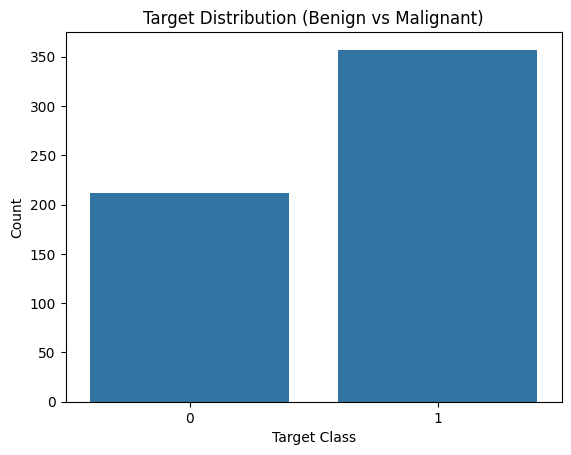

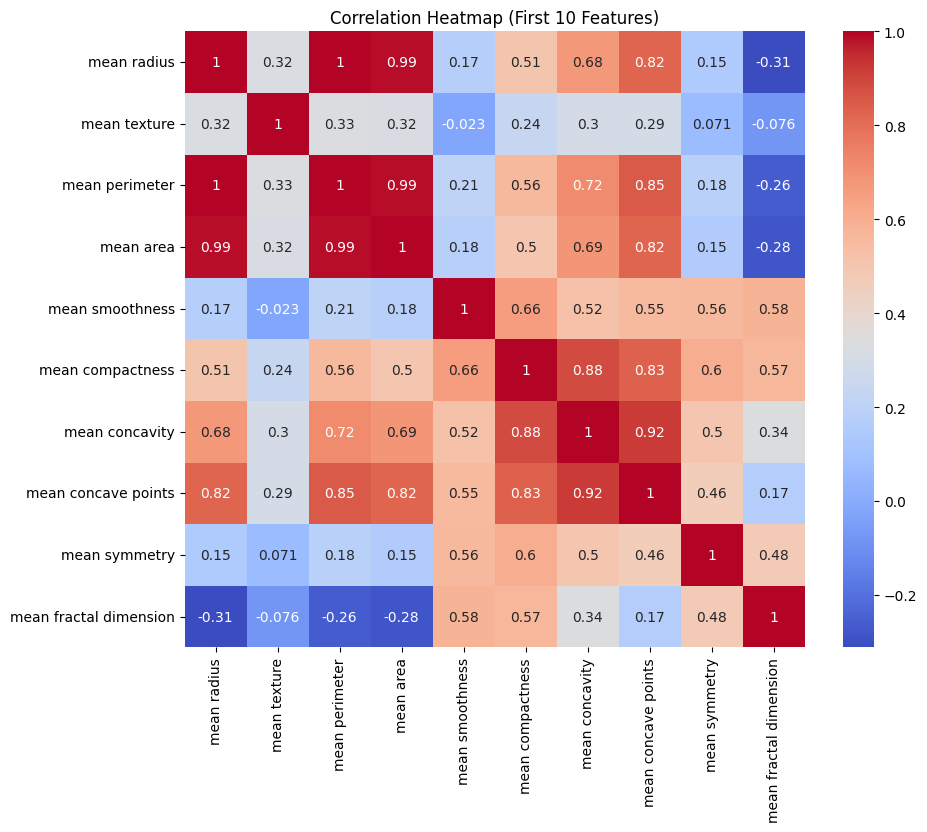

In [11]:
# TODO: Visualize the distribution of the target class
# TODO: Display a heatmap of the correlations between the first 10 features
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------------------
# Visualizing the distribution of the target variable
# ----------------------------------------
# Here I check how many samples belong to each class (0 and 1)
# This helps me understand if the dataset is balanced or not

sns.countplot(x='target', data=df_clf)
plt.title("Target Distribution (Benign vs Malignant)")
plt.xlabel("Target Class")
plt.ylabel("Count")
plt.show()


# ----------------------------------------
# Correlation Heatmap for the first 10 features
# ----------------------------------------
# Here I calculate the correlation between the first 10 features
# This helps me identify relationships between variables
# Highly correlated features may contain redundant information

corr = df_clf.iloc[:, :10].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap (First 10 Features)")
plt.show()


### 1.2 Model Training (Classification)
Train Logistic Regression, KNN, and Decision Tree. Compare them.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Split the data (80/20)
X = df_clf.drop('target', axis=1)
y = df_clf['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling (Required for LR and KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# TODO: Train the 3 models and print their Accuracy and F1-Score results in a comparison table.
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# ----------------------------------------
# Training the classification models
# ----------------------------------------
# I train three different models:
# 1. Logistic Regression
# 2. KNN
# 3. Decision Tree
# Logistic Regression and KNN use the scaled data because they are sensitive to feature scales.
# Decision Tree uses the original data because trees are not affected by scaling.

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = []

for model_name, model in models.items():

    # For Logistic Regression and KNN, I use the scaled data
    if model_name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    # For Decision Tree, I use the original data
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Save the results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "F1-Score": f1
    })

# Create a comparison table
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,F1-Score
0,Logistic Regression,0.973684,0.979021
1,KNN,0.947368,0.957746
2,Decision Tree,0.947368,0.957746


## Part 2: Regression - California Housing Prices
Predict the median house value in California districts.

In [13]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()
df_reg = pd.DataFrame(housing.data, columns=housing.feature_names)
df_reg['Price'] = housing.target
df_reg.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### 2.1 EDA - Regression
Explore price distribution and identify the most correlated feature.

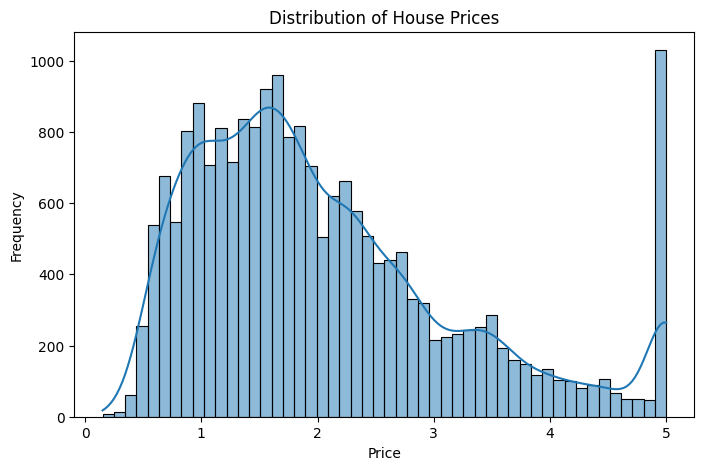

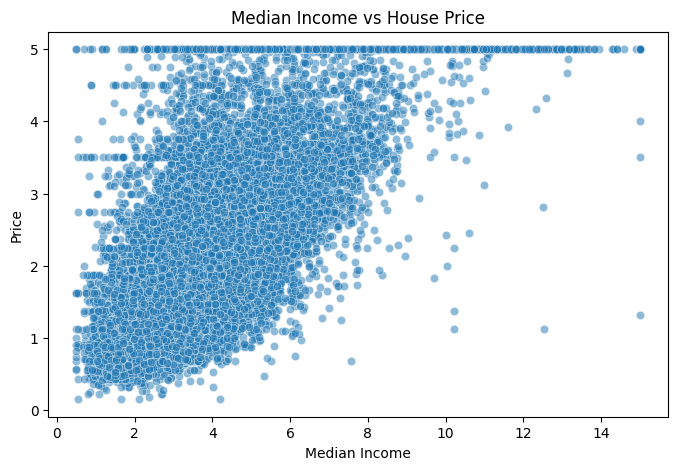

In [14]:
# TODO: Plot the distribution of house prices
# TODO: Create a scatter plot between 'MedInc' (Median Income) and 'Price'
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------------------
# Plotting the distribution of house prices
# ----------------------------------------
# Here I visualize the distribution of the target variable (Price)
# This helps me understand how the prices are spread (normal, skewed, etc.)

plt.figure(figsize=(8, 5))
sns.histplot(df_reg['Price'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()


# ----------------------------------------
# Scatter plot: Median Income vs Price
# ----------------------------------------
# Here I explore the relationship between Median Income (MedInc)
# and house prices to see if there is a correlation between them

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df_reg['MedInc'], y=df_reg['Price'], alpha=0.5)
plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Price")
plt.show()

### 2.2 Model Training (Regression)
Train Linear Regression, KNN Regressor, and Decision Tree Regressor.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

# TODO: Split, Scale, and Train the 3 regression models.
# TODO: Compare results using MSE and R2 Score.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# ----------------------------------------
# Splitting the regression data
# ----------------------------------------
# I separate the features (X) from the target variable (Price).
# Then I split the data into training and testing sets.

X = df_reg.drop('Price', axis=1)
y = df_reg['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# ----------------------------------------
# Scaling the data
# ----------------------------------------
# Scaling is important for Linear Regression and KNN Regressor.
# KNN is distance-based, so different feature scales can affect the results.
# Decision Tree does not need scaling.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ----------------------------------------
# Training the regression models
# ----------------------------------------
# I train three regression models:
# 1. Linear Regression
# 2. KNN Regressor
# 3. Decision Tree Regressor

models = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42)
}

results = []

for model_name, model in models.items():

    # Linear Regression and KNN use scaled data
    if model_name in ["Linear Regression", "KNN Regressor"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    # Decision Tree uses original data
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Evaluation metrics for regression
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MSE": mse,
        "R2 Score": r2
    })

# Create a comparison table
results_df_reg = pd.DataFrame(results)

results_df_reg

,Model,MSE,R2 Score
0,Linear Regression,0.555892,0.575788
1,KNN Regressor,0.432422,0.670010
2,Decision Tree Regressor,0.495235,0.622076


## Part 3: Conclusions

1. Which model performed best for classification?

The best performing model for classification is Logistic Regression,
as it achieved the highest Accuracy and F1-Score among all models.

2. Which model performed best for regression?

The best performing model for regression is KNN Regressor,
as it achieved the lowest MSE and the highest R2 score.

3. Why is scaling important for KNN but less critical for Decision Trees?

Scaling is important for KNN because it is a distance-based algorithm.
KNN calculates the distance between data points, and if features are on different scales,
features with larger values will dominate the distance calculation.

On the other hand, Decision Trees are not affected by feature scaling because they split the data
based on feature thresholds rather than distances. Therefore, the scale of the features does not impact the model’s decisions.

